In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [5]:
X, y = make_blobs(centers=np.random.uniform(-10, 10, (2, 2)), n_samples=[400, 100], n_features=2, shuffle=True, random_state=40)


In [3]:
print(X.shape)
print(y.shape)

(500, 2)
(500,)


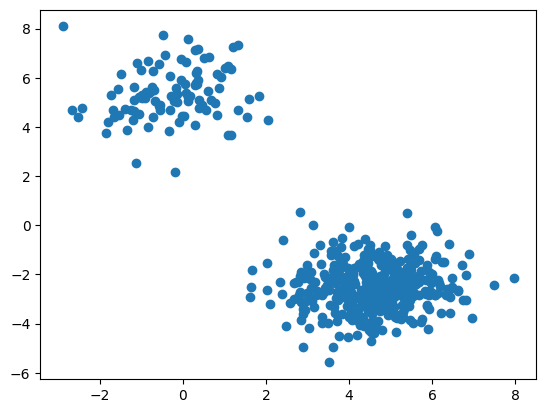

In [6]:
plt.scatter(X[:,0:1], X[:, 1:2])

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

1. Initialization: randomly pick four samples as centroids
2. Calculate the distance between every sample and four centroids, and create four clusters according to the closest samples to the centroids
3. According to the new created clusters, update the centroids.
4. Repeat Step 2, 3 for max_iters times, max_iters is the parameter indicate how many times you want to train the dataset

Define the distances caclualtion function

In [8]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

1. Initialization: randomly pick four samples as centroids

In [9]:
random_sample_idx = np.random.choice(X_train.shape[0], 4)
random_sample_idx

array([139, 246,  45,   7])

In [10]:
centroids = [X_train[idx] for idx in random_sample_idx]
centroids

[array([ 4.55758618, -1.96019091]),
 array([ 3.02381066, -4.18890122]),
 array([0.59251622, 5.4780116 ]),
 array([ 5.00770398, -1.68071682])]

2. Calculate the distance between every sample and four centroids, and create four clusters according to the closest samples to the centroids

In [11]:
def create_clusters(centroids):
  clusters = [[] for _ in range(4)]
  for idx, sample in enumerate(X_train):
    distances = [euclidean_distance(sample, point) for point in centroids]
    centroids_idx = np.argmin(distances)
    clusters[centroids_idx].append(idx)
  return clusters


3. According to the new created clusters, update the centroids.

In [12]:
def update_centroids(clusters):
  centroids = np.zeros((4, 2))
  for cluster_idx, cluster in enumerate(clusters):
    cluster_mean = np.mean(X_train[cluster], axis=0)
    centroids[cluster_idx] = cluster_mean
  return centroids

4. Repeat Step 2, 3 for max_iters times, max_iters is the parameter indicate how many times you want to train the dataset

In [13]:
def train(X_train, max_iters):
  random_sample_idx = np.random.choice(X_train.shape[0], 4)
  centroids = [X_train[idx] for idx in random_sample_idx]
  for i in range(max_iters):
    clusters = create_clusters(centroids)
    centroids = update_centroids(clusters)
    plot(X_train, clusters, centroids, i)
  return clusters, centroids

Define a function to plot clusters and centroids

In [15]:
def plot(X, clusters, centroids, iteration):
    color_list = ['red', 'blue', 'green', 'yellow']
    plt.figure()

    for cluster_idx, cluster in enumerate(clusters):
        for idx in cluster:
            plt.scatter(X[idx][0], X[idx][1], color=color_list[cluster_idx])

    for point in centroids:
        plt.scatter(*point, marker='x', color="black", linewidth=2)

    plt.title(f"Iteration {iteration}")
    plt.savefig(f"cluster_plot_{iteration}.png")
    plt.close()

In [16]:
clusters, centroids = train(X_train, 10)

Predict on test set and visualize the results

In [17]:
def predict(X_test, centroids):
    clusters = [[] for _ in range(4)]
    for idx, sample in enumerate(X_test):
      distances = [euclidean_distance(sample, point) for point in centroids]
      centroids_idx = np.argmin(distances)
      clusters[centroids_idx].append(idx)

    labels = np.empty(len(X_test))
    for cluster_idx, cluster in enumerate(clusters):
      for sample_index in cluster:
        labels[sample_index] = cluster_idx
    return clusters, labels

In [18]:
clusters, labels = predict(X_test, centroids)

In [20]:
plot(X_test, clusters, centroids, 1)